## Importar el CSV

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Descargar el CSV
!gdown https://drive.google.com/uc?id=1m3qM4ubHRM-o08aVslcJwqX-msiO_yy0

Downloading...
From: https://drive.google.com/uc?id=1m3qM4ubHRM-o08aVslcJwqX-msiO_yy0
To: /content/cardio_train.csv
100% 2.94M/2.94M [00:00<00:00, 23.7MB/s]


In [ ]:
# Definir el Path al CSV
csv_path = '/content/cardio_train.csv'

# Cargar el dataset especificando el separador por punto y coma
df = pd.read_csv(csv_path, sep=';')
display(df.head())

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


## Análisis Exploratorio al Dataset

In [ ]:
# Convertir la edad de días a años para una mejor legibilidad
df['age_years'] = (df['age'] / 365)

# Realizar el EDA
summary = {
    'Total de registros': len(df),
    'Valores faltantes': df.isnull().sum().sum(),
    'Edad promedio (años)': df['age_years'].mean().round(1),
    'Porcentaje por género (1: Mujer, 2: Hombre)': (
        df['gender'].value_counts(normalize=True) * 100
    ).round(1).to_dict(),
    'Altura promedio (cm)': df['height'].mean().round(1),
    'Peso promedio (kg)': df['weight'].mean().round(1),
    'Prevalencia de enfermedad cardiovascular (%)': (
        df['cardio'].mean() * 100
    ).round(1),
    'Colesterol alto (%)': (
        df['cholesterol'].apply(lambda x: 1 if x > 1 else 0).mean() * 100
    ).round(1),
    'Fumadores (%)': (df['smoke'].mean() * 100).round(1),
    'Consumidores de alcohol (%)': (df['alco'].mean() * 100).round(1),
    'Físicamente activos (%)': (df['active'].mean() * 100).round(1)
}

print("--- RESUMEN DEL ANÁLISIS EXPLORATORIO DE DATOS (EDA) ---")
for key, value in summary.items():
    print(f"{key}: {value}")

print("\n--- RESUMEN ESTADÍSTICO ---")
display(df.describe().T)

--- RESUMEN DEL ANÁLISIS EXPLORATORIO DE DATOS (EDA) ---
Total de registros: 70000
Valores faltantes: 0
Edad promedio (años): 53.3
Porcentaje por género (1: Mujer, 2: Hombre): {1: 65.0, 2: 35.0}
Altura promedio (cm): 164.4
Peso promedio (kg): 74.2
Prevalencia de enfermedad cardiovascular (%): 50.0
Colesterol alto (%): 25.2
Fumadores (%): 8.8
Consumidores de alcohol (%): 5.4
Físicamente activos (%): 80.4

--- RESUMEN ESTADÍSTICO ---


,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.000000,25006.750000,50001.500000,74889.250000,99999.000000
age,70000.0,19468.865814,2467.251667,10798.000000,17664.000000,19703.000000,21327.000000,23713.000000
gender,70000.0,1.349571,0.476838,1.000000,1.000000,1.000000,2.000000,2.000000
height,70000.0,164.359229,8.210126,55.000000,159.000000,165.000000,170.000000,250.000000
weight,70000.0,74.205690,14.395757,10.000000,65.000000,72.000000,82.000000,200.000000
ap_hi,70000.0,128.817286,154.011419,-150.000000,120.000000,120.000000,140.000000,16020.000000
ap_lo,70000.0,96.630414,188.472530,-70.000000,80.000000,80.000000,90.000000,11000.000000
cholesterol,70000.0,1.366871,0.680250,1.000000,1.000000,1.000000,2.000000,3.000000
gluc,70000.0,1.226457,0.572270,1.000000,1.000000,1.000000,1.000000,3.000000
smoke,70000.0,0.088129,0.283484,0.000000,0.000000,0.000000,0.000000,1.000000


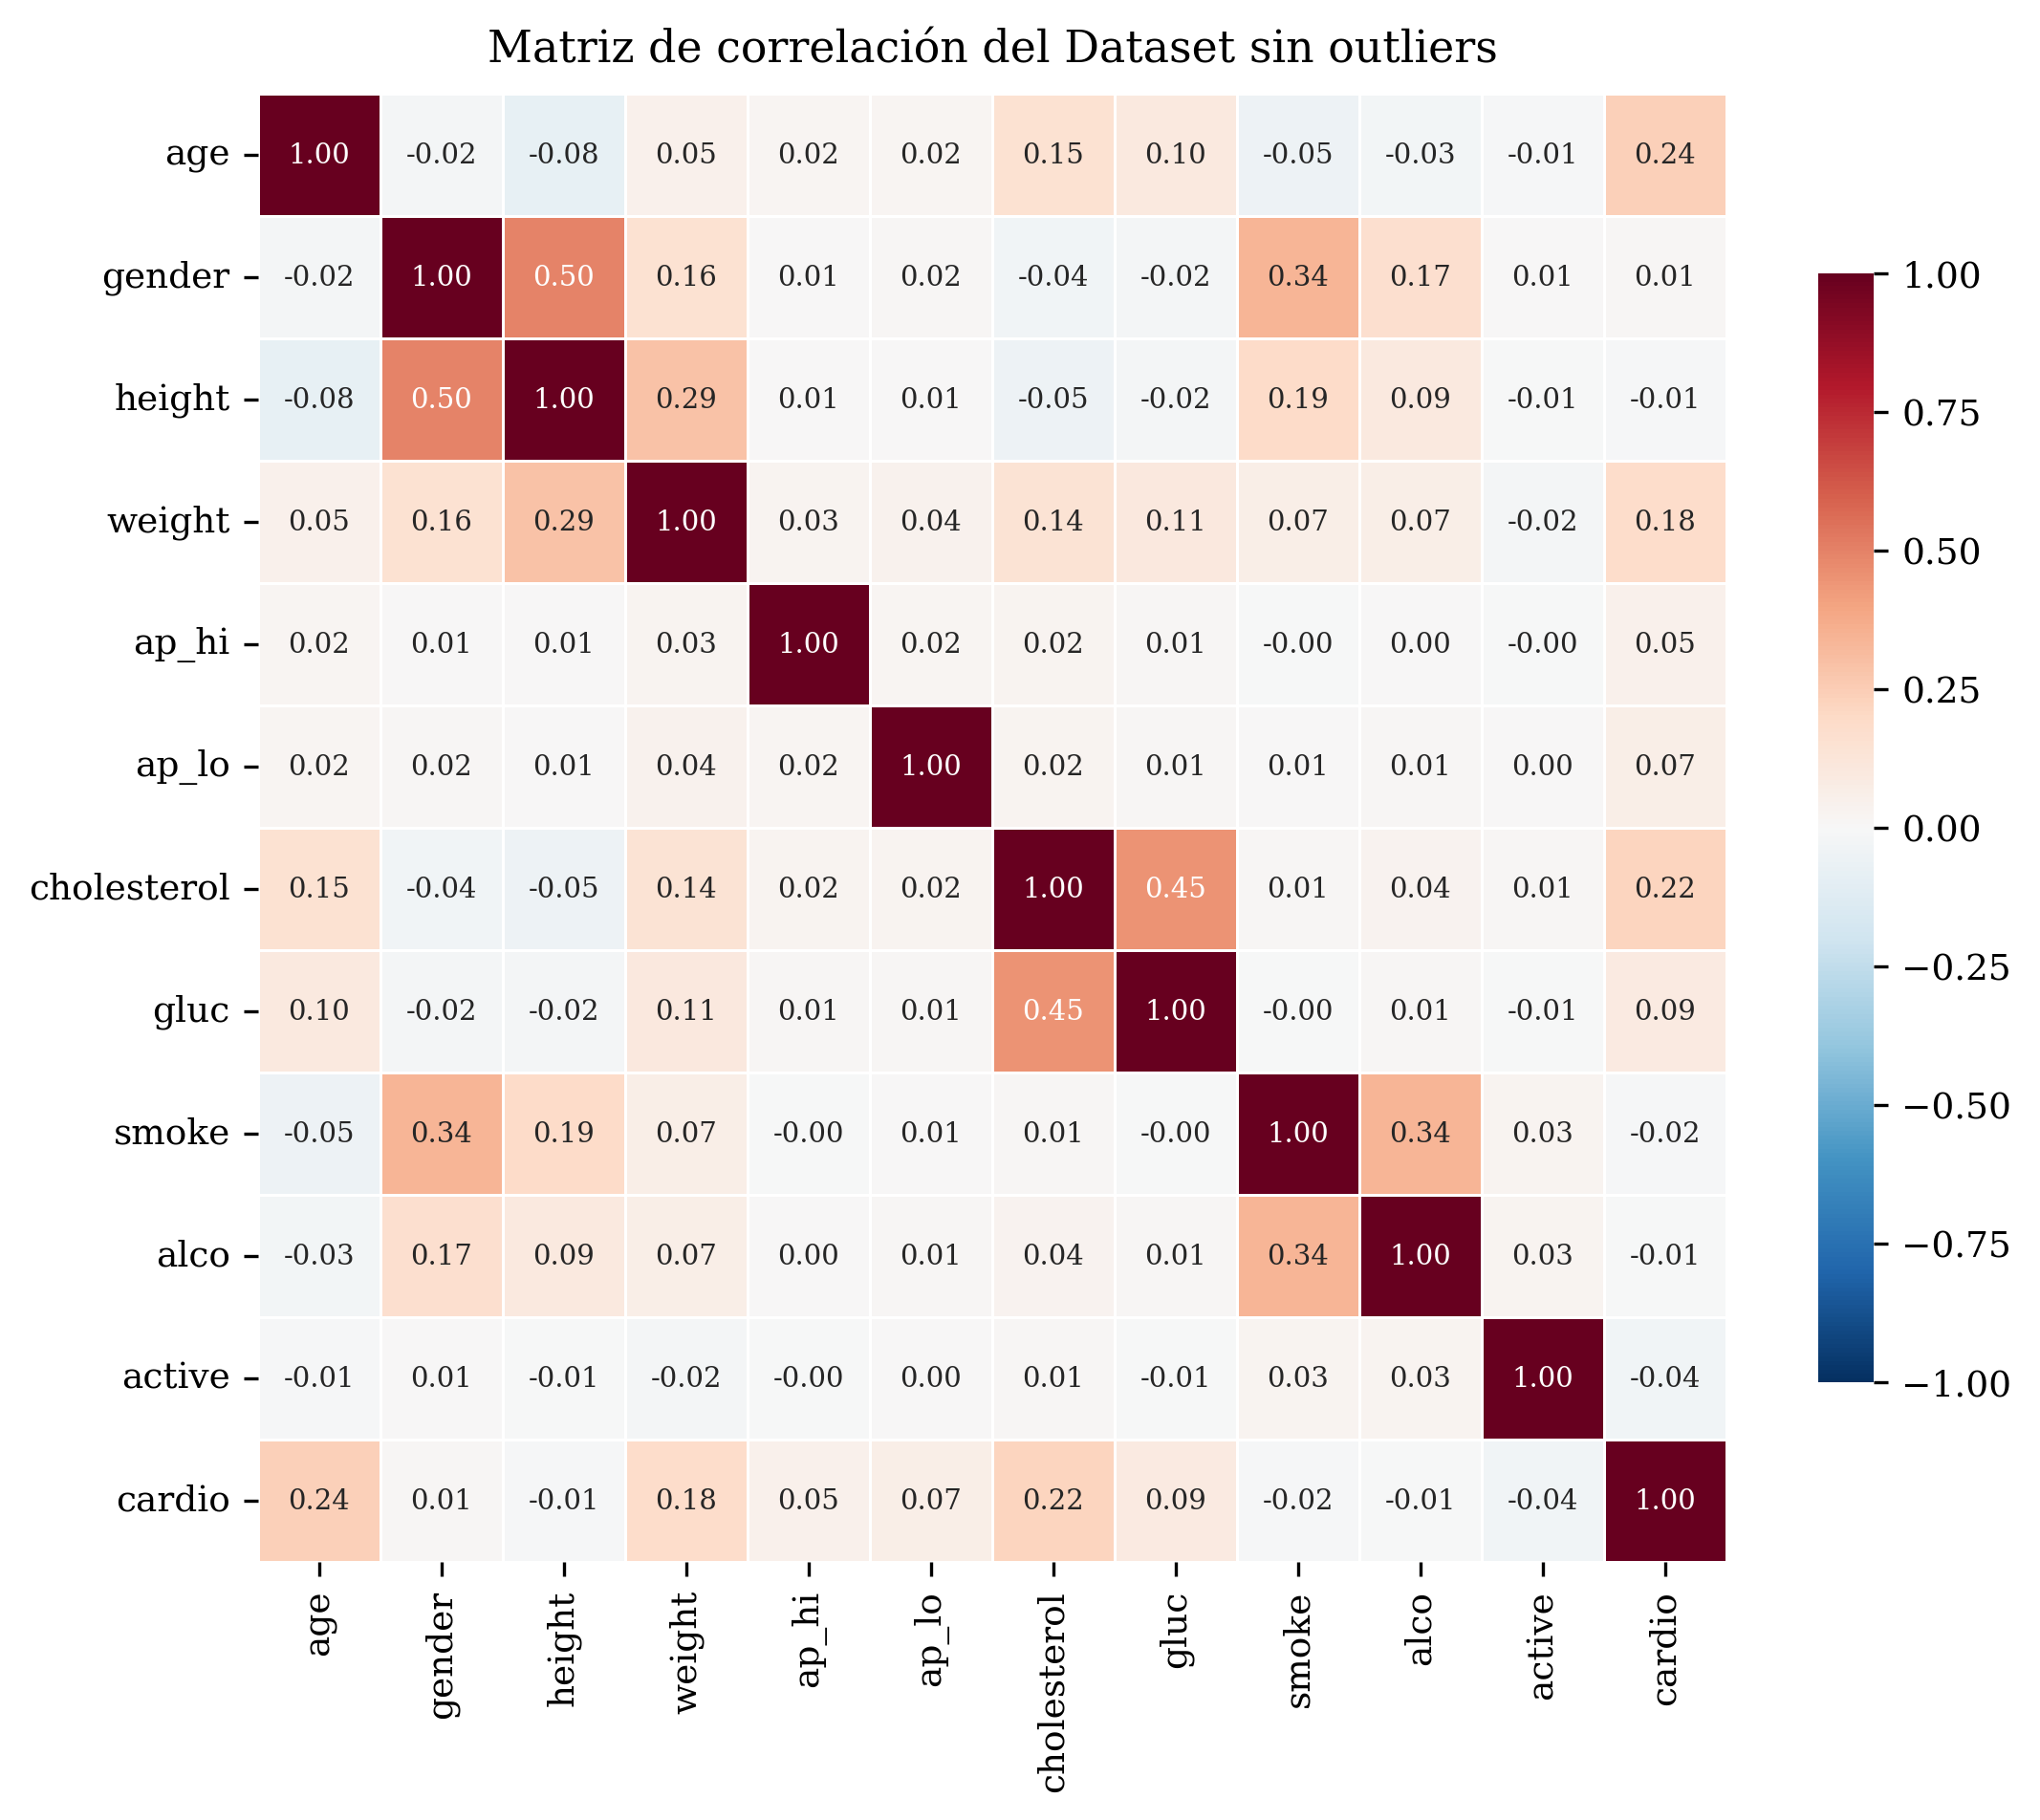

In [ ]:
# Configuración global estilo IEEE
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9
})

# Calcular la matriz de correlación excluyendo columnas no informativas
corr_matrix = df.drop(columns=['id', 'age_years']).corr()

# Crear la figura
fig, ax = plt.subplots(figsize=(7.5, 6.5), dpi=300)

# Dibujar el mapa de calor
sns.heatmap(
    corr_matrix,
    cmap='RdBu_r',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={
        "shrink": 0.7,
    },
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    ax=ax
)

# Título conciso y formal
ax.set_title("Matriz de correlación del Dataset sin outliers", pad=8)

# Ajustar layout para evitar recortes
plt.tight_layout()

plt.show()

**ANÁLISIS DE RESULTADOS**

1. El dataset es balanceado en cuanto a la variable objetivo
2. La población es mayoritariamente de mediana edad (48-58 años)
3. Hay un mayor número de mujeres
3. En cuanto a altura, peso y presión arterial, aparecen valores extremos e incluso irreales; se proponer hacer limpieza de estos

## Análisis Exploratorio del Dataset sin outliers

In [ ]:
# Definir los límites para el chequeo de sanidad
height_low, height_high = 100, 250
weight_low, weight_high = 40, 200
ap_hi_min, ap_hi_max = 50, 260
ap_lo_min, ap_lo_max = 0, 200

# Identificar filas con posibles medidas erróneas
outliers = df[
    (df['height'] < height_low) | (df['height'] > height_high) |
    (df['weight'] < weight_low) | (df['weight'] > weight_high) |
    (df['ap_hi'] < ap_hi_min) | (df['ap_hi'] > ap_hi_max) |
    (df['ap_lo'] < ap_lo_min) | (df['ap_hi'] > ap_lo_max) |
    (df['ap_hi'] < df['ap_lo'])
]

print(f"Total de registros con datos potencialmente erróneos: {len(outliers)}")
print(f"Porcentaje del conjunto de datos: {(len(outliers) / len(df) * 100):.2f}%")

# Mostrar conteos específicos para cada condición
print(f"- Altura fuera de rango: {len(df[(df['height'] < height_low) | (df['height'] > height_high)])}")
print(f"- Peso fuera de rango: {len(df[(df['weight'] < weight_low) | (df['weight'] > weight_high)])}")
print(f"- Presión sistólica (ap_hi) fuera de rango: "
      f"{len(df[(df['ap_hi'] < ap_hi_min) | (df['ap_hi'] > ap_hi_max)])}")
print(f"- Presión diastólica (ap_lo) fuera de rango: "
      f"{len(df[(df['ap_lo'] < ap_lo_min) | (df['ap_lo'] > ap_lo_max)])}")
print(f"- Sistólica menor que diastólica (ap_hi < ap_lo): "
      f"{len(df[df['ap_hi'] < df['ap_lo']])}")


Total de registros con datos potencialmente erróneos: 1407
Porcentaje del conjunto de datos: 2.01%
- Altura fuera de rango: 29
- Peso fuera de rango: 52
- Presión sistólica (ap_hi) fuera de rango: 228
- Presión diastólica (ap_lo) fuera de rango: 954
- Sistólica menor que diastólica (ap_hi < ap_lo): 1234


In [ ]:
# Crear una versión limpia del dataframe
# Se excluyen los índices encontrados en el dataframe de outliers
df_clean = df.drop(outliers.index)

print(f"Tamaño del conjunto de datos original: {len(df)}")
print(f"Tamaño del conjunto de datos limpio: {len(df_clean)}")
print(f"Registros eliminados: {len(df) - len(df_clean)}")

Tamaño del conjunto de datos original: 70000
Tamaño del conjunto de datos limpio: 68593
Registros eliminados: 1407


In [ ]:
# Convertir la edad de días a años para una mejor legibilidad
df_clean['age_years'] = (df_clean['age'] / 365)

# Realizar el EDA
summary = {
    'Total de registros': len(df_clean),
    'Valores faltantes': df_clean.isnull().sum().sum(),
    'Edad promedio (años)': df_clean['age_years'].mean().round(1),
    'Porcentaje por género (1: Mujer, 2: Hombre)': (
        df_clean['gender'].value_counts(normalize=True) * 100
    ).round(1).to_dict(),
    'Altura promedio (cm)': df_clean['height'].mean().round(1),
    'Peso promedio (kg)': df_clean['weight'].mean().round(1),
    'Prevalencia de enfermedad cardiovascular (%)': (
        df_clean['cardio'].mean() * 100
    ).round(1),
    'Colesterol alto (%)': (
        df_clean['cholesterol'].apply(lambda x: 1 if x > 1 else 0).mean() * 100
    ).round(1),
    'Fumadores (%)': (df_clean['smoke'].mean() * 100).round(1),
    'Consumidores de alcohol (%)': (df_clean['alco'].mean() * 100).round(1),
    'Físicamente activos (%)': (df_clean['active'].mean() * 100).round(1)
}

print("--- RESUMEN DEL ANÁLISIS EXPLORATORIO DE DATOS (EDA) ---")
for key, value in summary.items():
    print(f"{key}: {value}")

print("\n--- RESUMEN ESTADÍSTICO ---")
display(df_clean.describe().T)

--- RESUMEN DEL ANÁLISIS EXPLORATORIO DE DATOS (EDA) ---
Total de registros: 68593
Valores faltantes: 0
Edad promedio (años): 53.3
Porcentaje por género (1: Mujer, 2: Hombre): {1: 65.1, 2: 34.9}
Altura promedio (cm): 164.4
Peso promedio (kg): 74.1
Prevalencia de enfermedad cardiovascular (%): 49.5
Colesterol alto (%): 25.0
Fumadores (%): 8.8
Consumidores de alcohol (%): 5.3
Físicamente activos (%): 80.3

--- RESUMEN ESTADÍSTICO ---


,count,mean,std,min,25%,50%,75%,max
id,68593.0,49971.272681,28848.293236,0.000000,24997.000000,50013.000000,74868.000000,99999.000000
age,68593.0,19463.428105,2468.514074,10798.000000,17656.000000,19700.000000,21324.000000,23713.000000
gender,68593.0,1.348651,0.476547,1.000000,1.000000,1.000000,2.000000,2.000000
height,68593.0,164.403117,7.973115,100.000000,159.000000,165.000000,170.000000,250.000000
weight,68593.0,74.133839,14.273759,40.000000,65.000000,72.000000,82.000000,200.000000
ap_hi,68593.0,126.613547,16.505802,60.000000,120.000000,120.000000,140.000000,200.000000
ap_lo,68593.0,81.239922,9.563143,0.000000,80.000000,80.000000,90.000000,182.000000
cholesterol,68593.0,1.364483,0.678816,1.000000,1.000000,1.000000,1.000000,3.000000
gluc,68593.0,1.225548,0.571431,1.000000,1.000000,1.000000,1.000000,3.000000
smoke,68593.0,0.087939,0.283208,0.000000,0.000000,0.000000,0.000000,1.000000


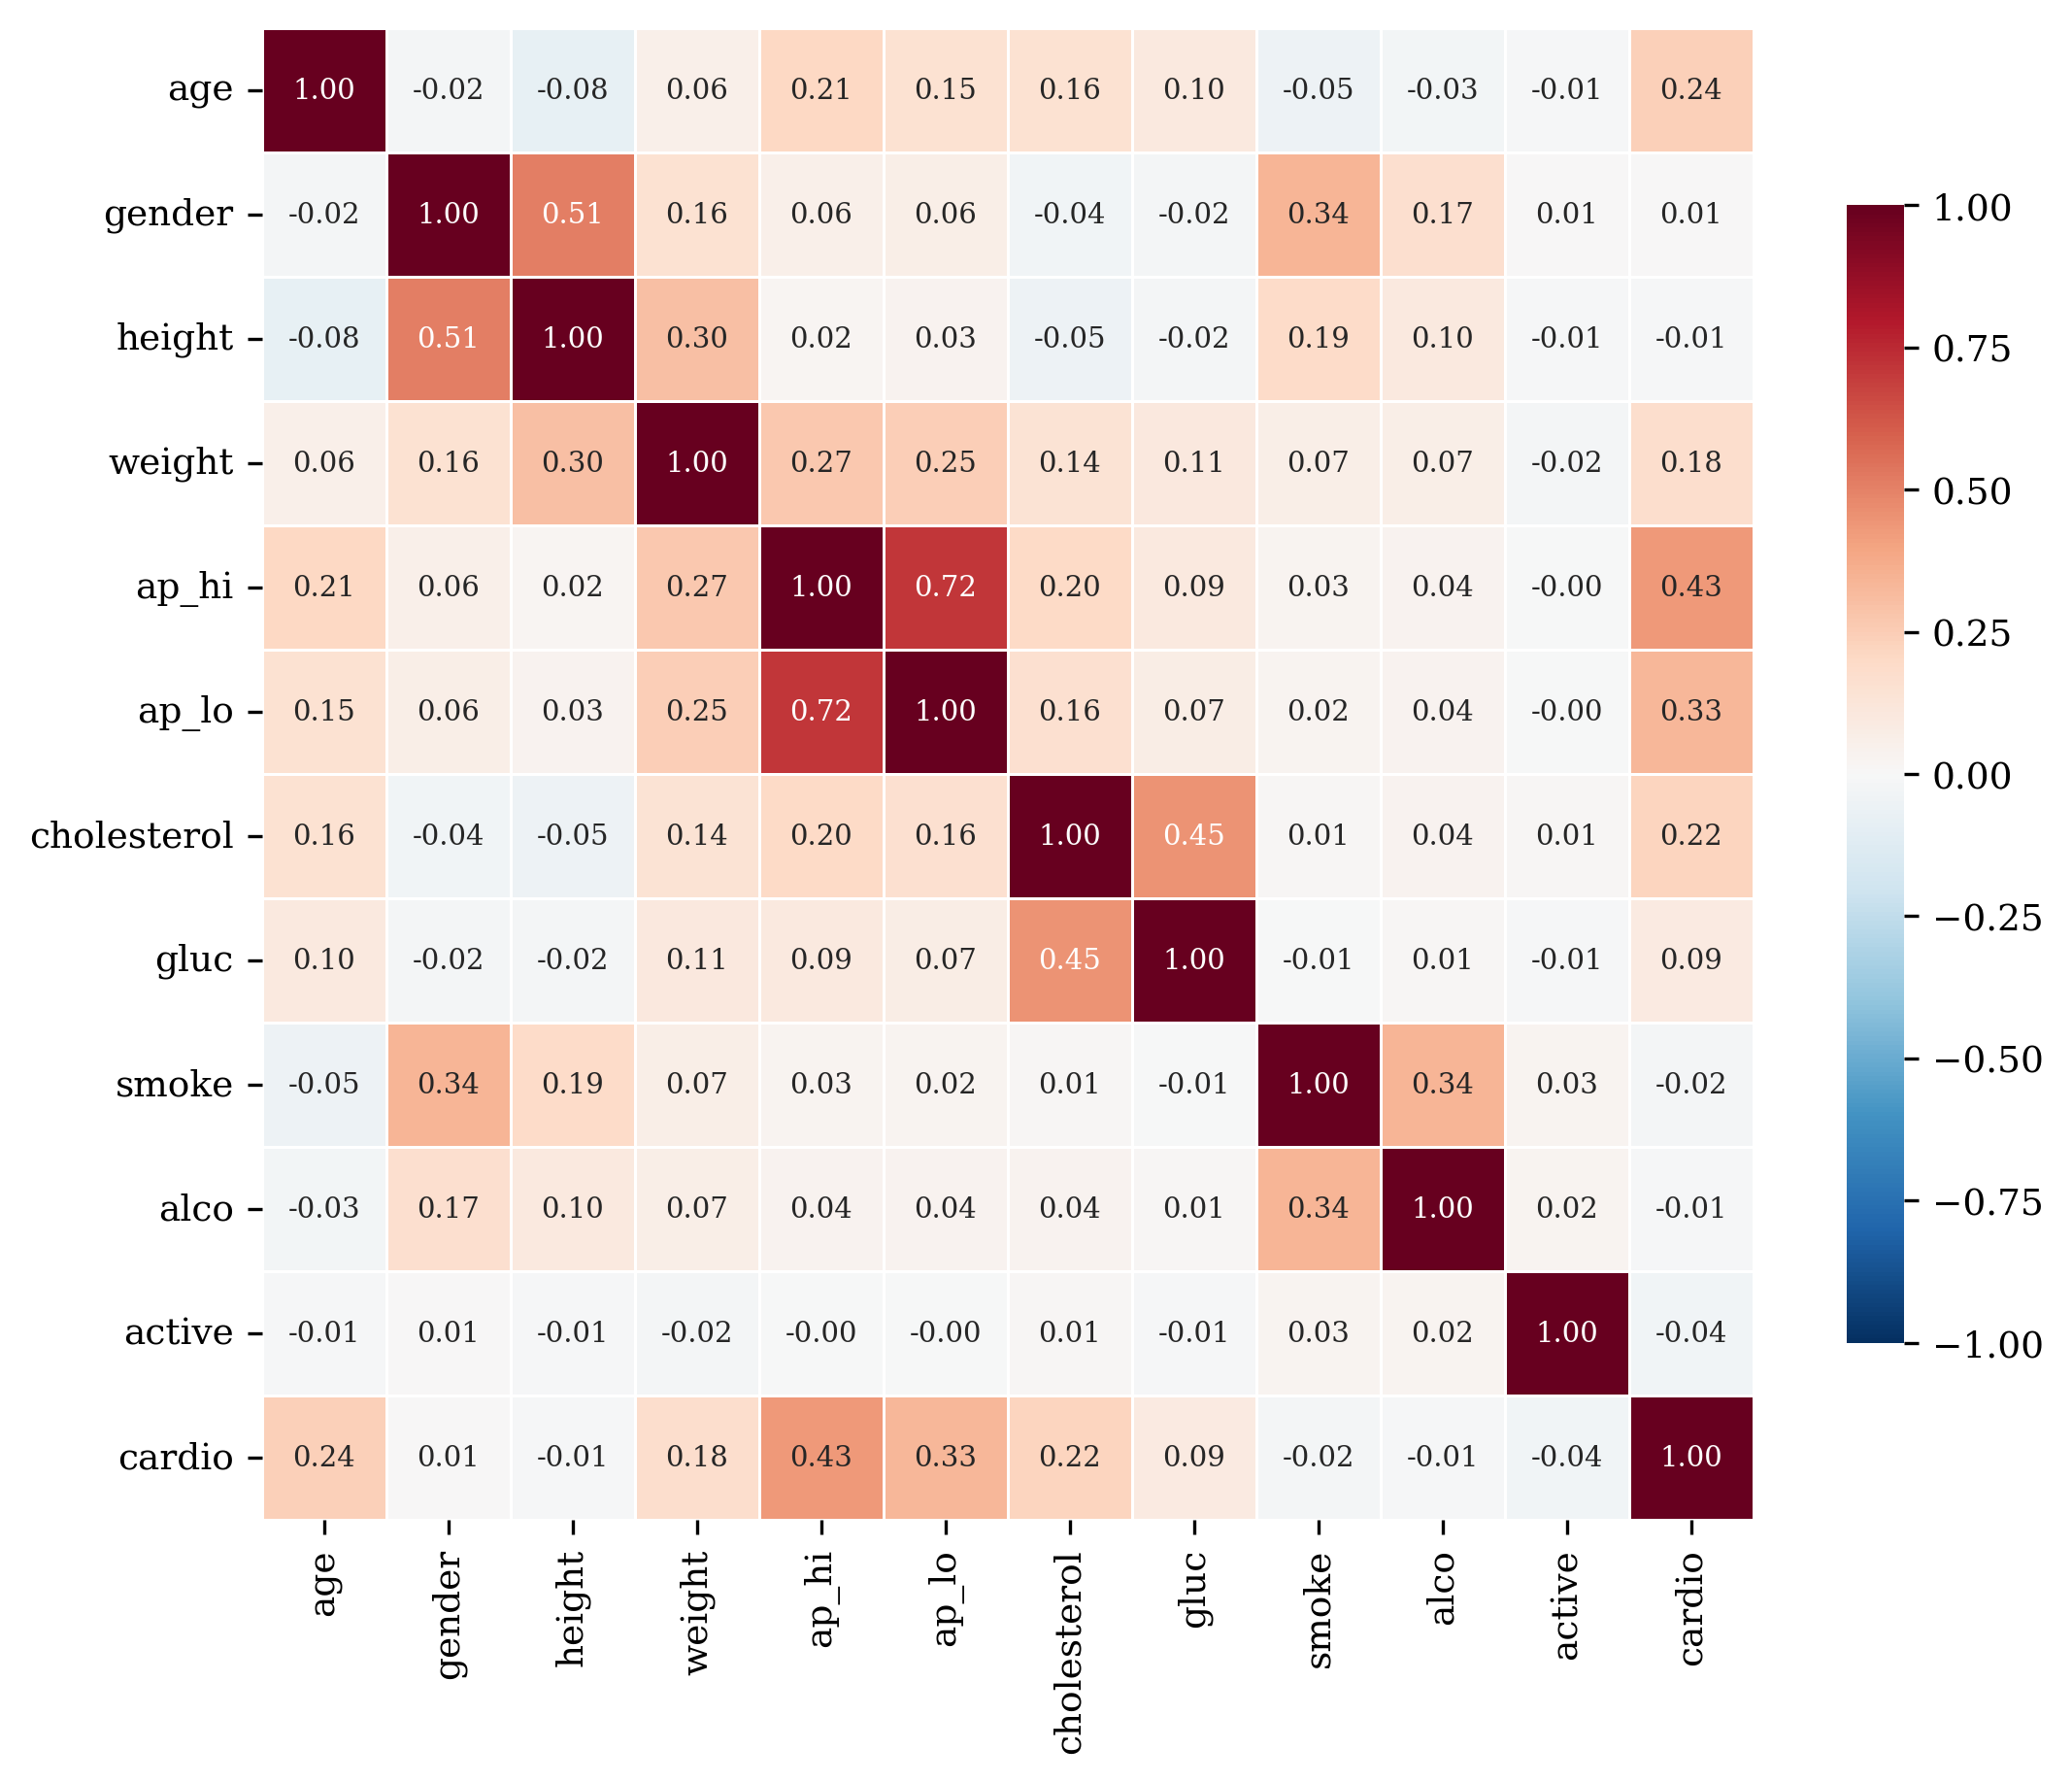

In [ ]:
# Configuración global estilo IEEE
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9
})

# Calcular la matriz de correlación excluyendo columnas no informativas
corr_matrix = df_clean.drop(columns=['id', 'age_years']).corr()

# Crear la figura
fig, ax = plt.subplots(figsize=(7.5, 6.5), dpi=300)

# Dibujar el mapa de calor
sns.heatmap(
    corr_matrix,
    cmap='RdBu_r',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={
        "shrink": 0.7,
    },
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    ax=ax
)

# Ajustar layout para evitar recortes
plt.tight_layout()

plt.show()

**ANÁLISIS DE RESULTADOS**

1. El dataset sigue siendo balanceado en cuanto a la variable objetivo
2. La población sigue siendo mayoritariamente de mediana edad
3. Sigue habiendo un mayor número de mujeres
3. En cuanto a altura, peso y presión arterial, los valores mínimos y máximo ahora tienen sentido
4. Ahora hay una mayor correlación entre presión sistólica y diástolica, lo cual tiene sentido
5. Aparece una mayor correlación entre presión arterial y enfermedad cardiovascular
6. No hay valores faltantes

